# Análisis de datos con Python

## Contenido:

1. Adquisición de datos
2. Caracterización de datos: Cuantitativos/Cualitativos, Numéricos/Categóricos
3. Análsis de datos continuos por distribuciones
4. Análisis de datos discretos por clases
5. Análisis cruzado entre datos continuos y discretos

In [ ]:
# Manipular datos
import numpy
import pandas

# Visualizar datos
from matplotlib import pyplot
import seaborn

In [ ]:
titanic = pandas.read_csv("titanic.csv")

# DataFrame -> TABLA / COLUMNAS -> SERIES
titanic

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [ ]:
titanic["Name"] # Columna de los nombres

,Name
0,"Braund, Mr. Owen Harris"
1,"Cumings, Mrs. John Bradley (Florence Briggs Th..."
2,"Heikkinen, Miss. Laina"
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)"
4,"Allen, Mr. William Henry"
...,...
886,"Montvila, Rev. Juozas"
887,"Graham, Miss. Margaret Edith"
888,"Johnston, Miss. Catherine Helen ""Carrie"""
889,"Behr, Mr. Karl Howell"


In [ ]:
titanic["Cabin"]

,Cabin
0,NaN
1,C85
2,NaN
3,C123
4,NaN
...,...
886,NaN
887,B42
888,NaN
889,C148


In [ ]:
titanic["Cabin"].isna()

,Cabin
0,True
1,False
2,True
3,False
4,True
...,...
886,True
887,False
888,True
889,False


In [ ]:
~(titanic["Cabin"].isna())

,Cabin
0,False
1,True
2,False
3,True
4,False
...,...
886,False
887,True
888,False
889,True


In [ ]:
# Caracterización
# Característica: Serie/Eje de datos

c1 = titanic["Survived"] # 891 valores con 0 o 1
c2 = titanic["Pclass"] # 891 valores con 1 (primera), 2 (segunda) y 3 (tercera)
c3 = titanic["Age"] # 714 valores del 0.42 al 80 !!! Los valores están corruptos
c4 = titanic["Sex"] # 891 valores con "male" o "female"
c5 = titanic["SibSp"] # 891 valores con el total de familiares hermanos o cónyuges
c6 = titanic["Parch"] # 891 valores con el total de familiares padres o hijos
c7 = titanic["Fare"] # 891 valores con las tarifas
c8 = ~(titanic["Cabin"].isna()) # 891 valores si tiene cabina
c9 = titanic["Embarked"] # 891 valores con el puerto de embarcación "Q", "C", "S"

# Contexto: En titanic viajaron cerca de 2,500 personas por 1910
# Y solo se tiene el registro real de 891 pasajeros con
# sus características y supervivencia

In [ ]:
c1.info()

<class 'pandas.core.series.Series'>
RangeIndex: 891 entries, 0 to 890
Series name: Survived
Non-Null Count  Dtype
--------------  -----
891 non-null    int64
dtypes: int64(1)
memory usage: 7.1 KB


> Tratamiento de una característica continua

<Axes: ylabel='Density'>

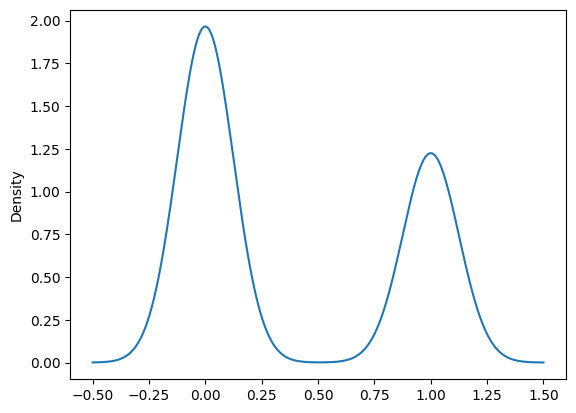

In [ ]:
c1.plot.density()

> Tratamiento de una característica discreta

<Axes: ylabel='Survived'>

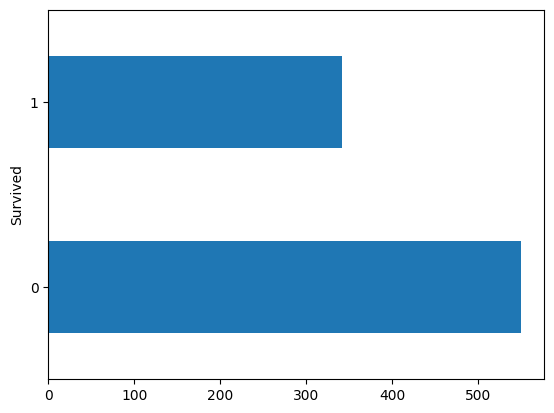

In [ ]:
c1.value_counts().plot.barh() # NO:SI -> 5:3 (5/8 vs 3/8) (62% vs 38%)

In [ ]:
c1.value_counts() # SOPORTE de cada clase

,count
Survived,
0,549
1,342


In [ ]:
c1.value_counts(normalize=True) # PROPORCIÓN de cada clase

,proportion
Survived,
0,0.616162
1,0.383838


In [ ]:
c2.info()

<class 'pandas.core.series.Series'>
RangeIndex: 891 entries, 0 to 890
Series name: Pclass
Non-Null Count  Dtype
--------------  -----
891 non-null    int64
dtypes: int64(1)
memory usage: 7.1 KB


> Tratamiento continuo: distribución

<Axes: ylabel='Density'>

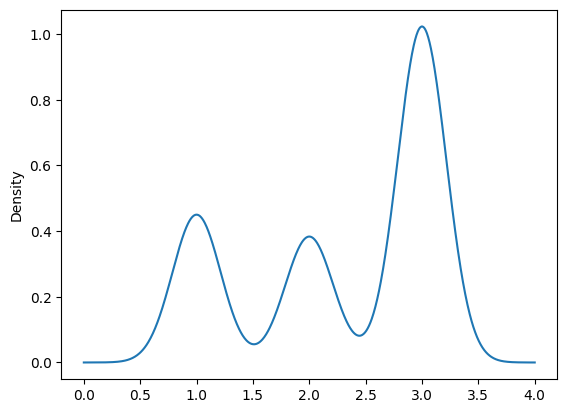

In [ ]:
c2.plot.density()

> Tratamiento discreto: Soporte y Proporción

<Axes: ylabel='Pclass'>

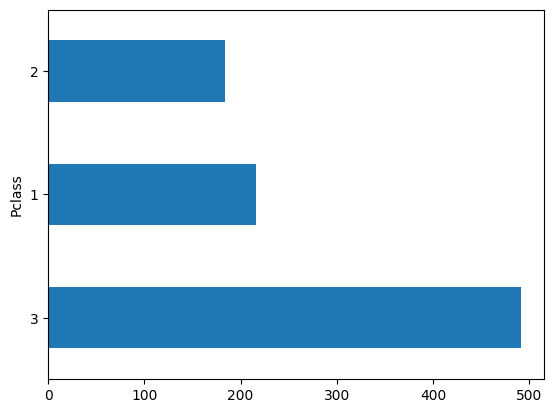

In [ ]:
c2.value_counts().plot.barh() # 3ra:1ra 5:2 (5/7 vs 2/7) (72% vs 28%)

In [ ]:
c2.value_counts() # SOPORTE por clase

,count
Pclass,
3,491
1,216
2,184


In [ ]:
c2.value_counts(normalize=True) # PROPORCIÓN por clase

,proportion
Pclass,
3,0.551066
1,0.242424
2,0.206510


In [ ]:
c3.info()

<class 'pandas.core.series.Series'>
RangeIndex: 891 entries, 0 to 890
Series name: Age
Non-Null Count  Dtype  
--------------  -----  
714 non-null    float64
dtypes: float64(1)
memory usage: 7.1 KB


> Tratamiento continuo: Distribución

<Axes: ylabel='Density'>

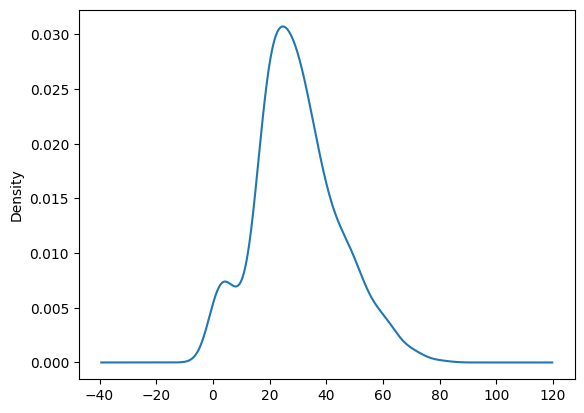

In [ ]:
c3.plot.density()

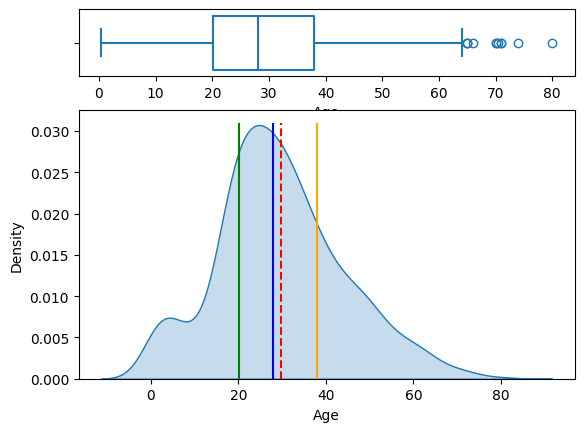

In [ ]:
from matplotlib import pyplot

figure, (ax1, ax2) = pyplot.subplots(2, 1, height_ratios=(1, 4))

seaborn.boxplot(x=c3, fill=False, ax=ax1)
seaborn.kdeplot(x=c3, fill=True, ax=ax2) # Kernel Density Estimation (KDE)

pyplot.vlines(c3.mean(), 0, 0.031, color="red", linestyle="--")
pyplot.vlines(c3.median(), 0, 0.031, color="blue", linestyle="-")
pyplot.vlines(c3.quantile(0.25), 0, 0.031, color="green", linestyle="-")
pyplot.vlines(c3.quantile(0.75), 0, 0.031, color="orange", linestyle="-")

pyplot.show()

In [ ]:
c5.info()

<class 'pandas.core.series.Series'>
RangeIndex: 891 entries, 0 to 890
Series name: SibSp
Non-Null Count  Dtype
--------------  -----
891 non-null    int64
dtypes: int64(1)
memory usage: 7.1 KB


<Axes: ylabel='Density'>

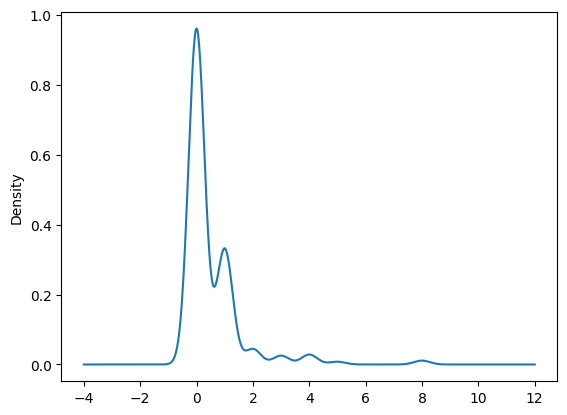

In [ ]:
c5.plot.density()

<Axes: ylabel='SibSp'>

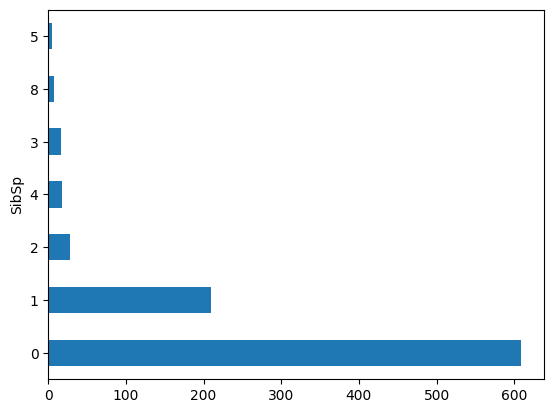

In [ ]:
c5.value_counts().plot.barh()

In [ ]:
c5.value_counts()

,count
SibSp,
0,608
1,209
2,28
4,18
3,16
8,7
5,5


## Análisis cruzado

Continuo vs Continuo

Continuo vs Discreto

Discreto vs Continuo

Discreto vs Discreto

<Axes: xlabel='Age', ylabel='Fare'>

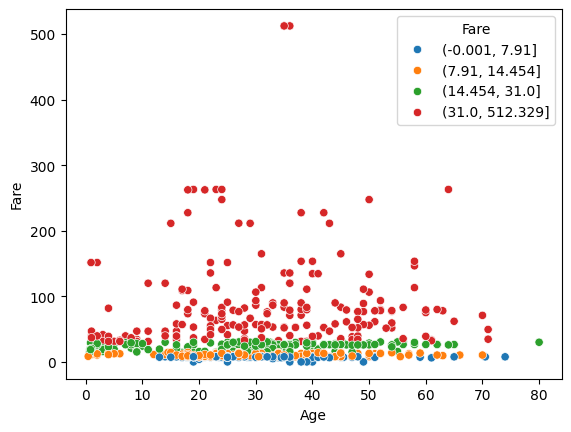

In [ ]:
# Continuo vs Continuo: Puntos de correlación

tarifas = pandas.qcut(c7, q=(0, 0.25, 0.5, 0.75, 1))

seaborn.scatterplot(x=c3, y=c7, hue=tarifas) # Patrones de linealidad

<Axes: xlabel='Age', ylabel='Density'>

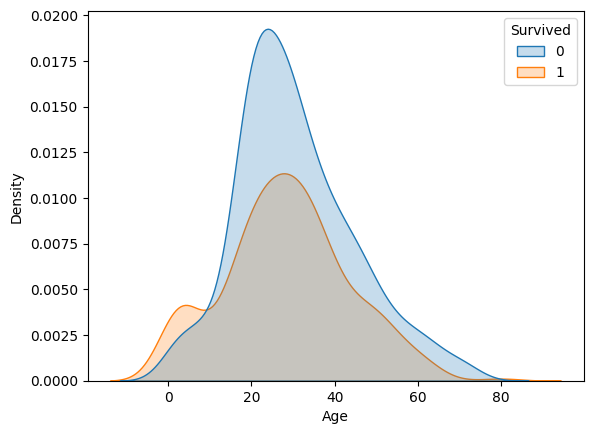

In [ ]:
# Continuo vs Discreto: Densidad por clases

# EDAD vs SUPERVIVENCIA
# x - continuo | hue - discreto
seaborn.kdeplot(x=c3, hue=c1, fill=True)

<Axes: xlabel='Survived', ylabel='Age'>

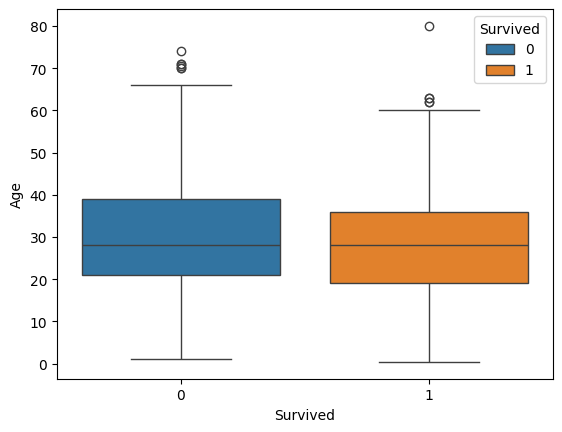

In [ ]:
# Discreto vs Continuo: Cajas por clases

# SUPERVIVENCIA vs EDAD
# x - discreto | y - continuo | hue - discreto
seaborn.boxplot(x=c1, y=c3, hue=c1)

In [ ]:
# Discreto vs Discreto: Mapa de calor | Matriz de conteos y proporciones

M = pandas.DataFrame({
    "Survived": c1,
    "Sex": c4,
}).groupby(["Survived", "Sex"]).size().unstack() # Unstack -> Formato ancho

R1 = M.divide(M.sum(axis=0), axis=1)
R2 = M.divide(M.sum(axis=1), axis=0)

M

Sex,female,male
Survived,,
0,81,468
1,233,109


In [ ]:
R1

Sex,female,male
Survived,,
0,0.257962,0.811092
1,0.742038,0.188908


In [ ]:
R2

Sex,female,male
Survived,,
0,0.147541,0.852459
1,0.681287,0.318713


<Axes: xlabel='Sex', ylabel='Survived'>

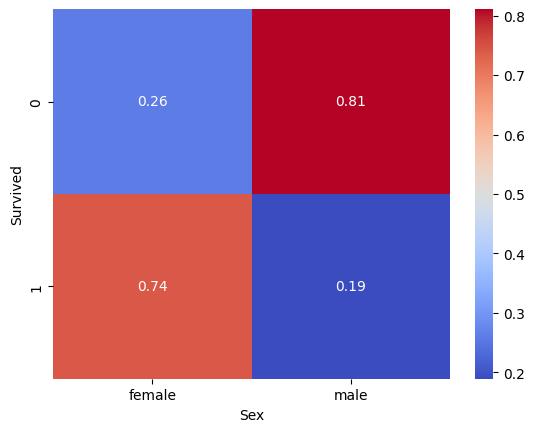

In [ ]:
seaborn.heatmap(R1, cmap="coolwarm", annot=True)